In [33]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset from the absolute path specified
file_path = '/Bengaluru_House_Data.csv'
df = pd.read_csv(file_path)

df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [34]:
df.shape

(13320, 9)

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [36]:
df.isnull().sum()

,0
area_type,0
availability,0
location,1
size,16
society,5502
total_sqft,0
bath,73
balcony,609
price,0


In [37]:
df['area_type'].value_counts()

,count
area_type,
Super built-up Area,8790
Built-up Area,2418
Plot Area,2025
Carpet Area,87


In [38]:
df2 = df.drop(['society', 'balcony'], axis=1)
df2 = df2.dropna()
df2.isnull().sum()

,0
area_type,0
availability,0
location,0
size,0
total_sqft,0
bath,0
price,0


In [39]:
df2['bhk'] = df2['size'].apply(lambda x: int(x.split(' ')[0]))
df2['bhk'].unique()

array([ 2,  4,  3,  6,  1,  8,  7,  5, 11,  9, 27, 10, 19, 16, 43, 14, 12,
       13, 18])

In [40]:
def is_float(x):
    try:
        float(x)
        return True
    except:
        return False

df2[~df2['total_sqft'].apply(is_float)].head(10)

,area_type,availability,location,size,total_sqft,bath,price,bhk
30,Super built-up Area,19-Dec,Yelahanka,4 BHK,2100 - 2850,4.0,186.000,4
122,Super built-up Area,18-Mar,Hebbal,4 BHK,3067 - 8156,4.0,477.000,4
137,Super built-up Area,19-Mar,8th Phase JP Nagar,2 BHK,1042 - 1105,2.0,54.005,2
165,Super built-up Area,18-Dec,Sarjapur,2 BHK,1145 - 1340,2.0,43.490,2
188,Super built-up Area,Ready To Move,KR Puram,2 BHK,1015 - 1540,2.0,56.800,2
410,Super built-up Area,Ready To Move,Kengeri,1 BHK,34.46Sq. Meter,1.0,18.500,1
549,Super built-up Area,18-Sep,Hennur Road,2 BHK,1195 - 1440,2.0,63.770,2
648,Built-up Area,Ready To Move,Arekere,9 Bedroom,4125Perch,9.0,265.000,9
661,Super built-up Area,Ready To Move,Yelahanka,2 BHK,1120 - 1145,2.0,48.130,2
672,Built-up Area,18-Mar,Bettahalsoor,4 Bedroom,3090 - 5002,4.0,445.000,4


In [41]:
def convert_sqft(x):
    tokens = x.split('-')
    if len(tokens) == 2:
        return (float(tokens[0]) + float(tokens[1])) / 2
    try:
        return float(x)
    except:
        return None

df3 = df2.copy()
df3['total_sqft'] = df3['total_sqft'].apply(convert_sqft)
df3 = df3.dropna()
df3['price_per_sqft'] = df3['price'] * 100000 / df3['total_sqft']
print(df3.shape)
df3.head()

(13200, 9)


,area_type,availability,location,size,total_sqft,bath,price,bhk,price_per_sqft
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056.0,2.0,39.07,2,3699.810606
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600.0,5.0,120.00,4,4615.384615
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440.0,2.0,62.00,3,4305.555556
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521.0,3.0,95.00,3,6245.890861
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200.0,2.0,51.00,2,4250.000000


In [42]:
df3['location'] = df3['location'].apply(lambda x: x.strip())
location_counts = df3['location'].value_counts()
print(len(location_counts))
location_counts.head(10)

1287


,count
location,
Whitefield,533
Sarjapur Road,392
Electronic City,304
Kanakpura Road,264
Thanisandra,235
Yelahanka,210
Uttarahalli,186
Hebbal,176
Marathahalli,175


In [43]:
rare = location_counts[location_counts <= 10]
df3['location'] = df3['location'].apply(lambda x: 'other' if x in rare else x)
df3['location'].nunique()

241

In [44]:
df3[df3['total_sqft'] / df3['bhk'] < 300].head(10)

,area_type,availability,location,size,total_sqft,bath,price,bhk,price_per_sqft
9,Plot Area,Ready To Move,other,6 Bedroom,1020.0,6.0,370.0,6,36274.509804
45,Plot Area,Ready To Move,HSR Layout,8 Bedroom,600.0,9.0,200.0,8,33333.333333
58,Plot Area,Ready To Move,Murugeshpalya,6 Bedroom,1407.0,4.0,150.0,6,10660.980810
68,Plot Area,Ready To Move,Devarachikkanahalli,8 Bedroom,1350.0,7.0,85.0,8,6296.296296
70,Plot Area,Ready To Move,other,3 Bedroom,500.0,3.0,100.0,3,20000.000000
78,Built-up Area,Ready To Move,Kaval Byrasandra,2 BHK,460.0,1.0,22.0,2,4782.608696
89,Plot Area,Ready To Move,Rajaji Nagar,6 Bedroom,710.0,6.0,160.0,6,22535.211268
119,Plot Area,Ready To Move,Hennur Road,2 Bedroom,276.0,3.0,23.0,2,8333.333333
129,Plot Area,Ready To Move,Vishwapriya Layout,7 Bedroom,950.0,7.0,115.0,7,12105.263158
149,Plot Area,Ready To Move,other,6 Bedroom,1034.0,5.0,185.0,6,17891.682785


In [45]:
print(df3.shape)
df4 = df3[~(df3['total_sqft'] / df3['bhk'] < 300)]
print(df4.shape)

(13200, 9)
(12456, 9)


In [46]:
def remove_pps_outliers(df):
    out = pd.DataFrame()
    for key, subdf in df.groupby('location'):
        m = subdf['price_per_sqft'].mean()
        st = subdf['price_per_sqft'].std()
        reduced = subdf[(subdf['price_per_sqft'] > (m - st)) & (subdf['price_per_sqft'] <= (m + st))]
        out = pd.concat([out, reduced], ignore_index=True)
    return out

df5 = remove_pps_outliers(df4)
print(df5.shape)

(10293, 9)


In [47]:
df5 = df5[df5['bath'] < df5['bhk'] + 2]
print(df5.shape)

(10198, 9)


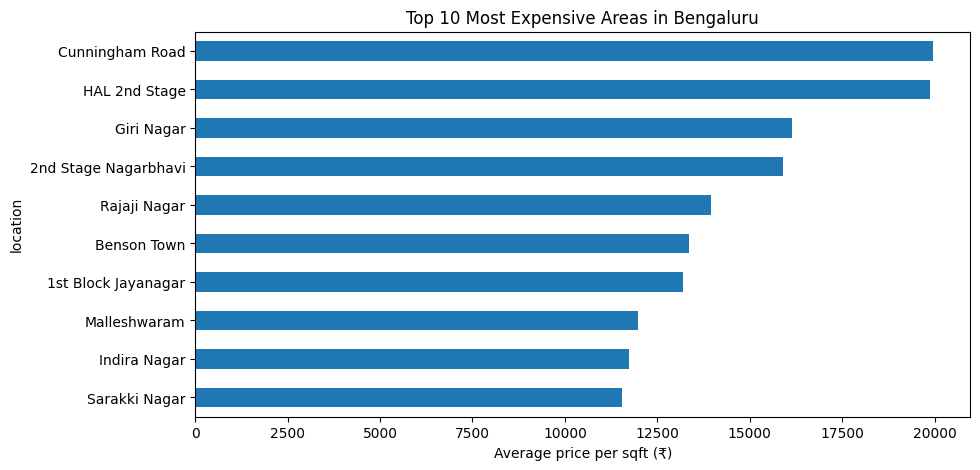

In [48]:
loc_price = (df5[df5['location'] != 'other']
             .groupby('location')['price_per_sqft']
             .mean()
             .sort_values(ascending=False))

plt.figure(figsize=(10, 5))
loc_price.head(10).sort_values().plot(kind='barh')
plt.title('Top 10 Most Expensive Areas in Bengaluru')
plt.xlabel('Average price per sqft (₹)')
plt.show()

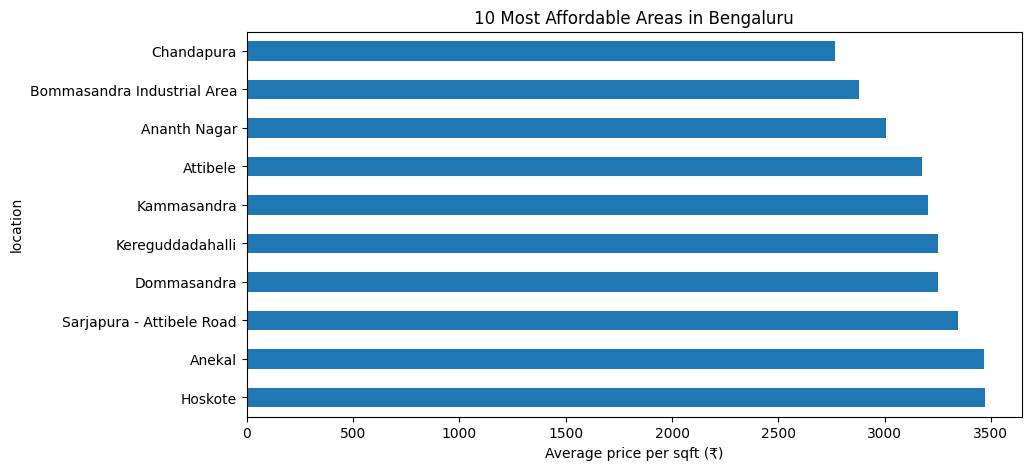

In [49]:
plt.figure(figsize=(10, 5))
loc_price.tail(10).sort_values(ascending=False).plot(kind='barh')
plt.title('10 Most Affordable Areas in Bengaluru')
plt.xlabel('Average price per sqft (₹)')
plt.show()

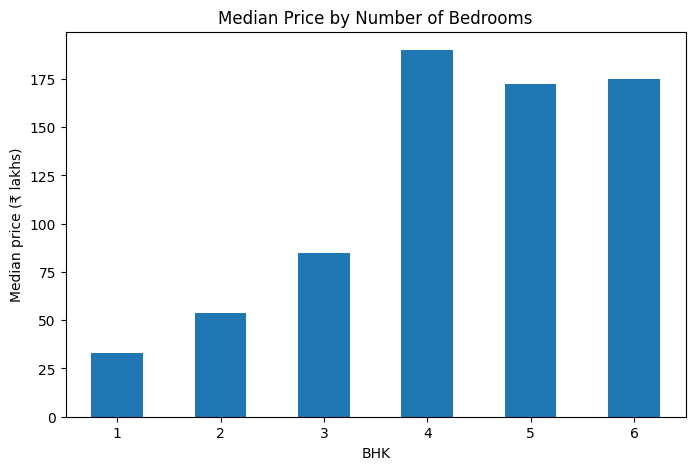

In [50]:
bhk_price = df5[df5['bhk'] <= 6].groupby('bhk')['price'].median()

plt.figure(figsize=(8, 5))
bhk_price.plot(kind='bar')
plt.title('Median Price by Number of Bedrooms')
plt.xlabel('BHK')
plt.ylabel('Median price (₹ lakhs)')
plt.xticks(rotation=0)
plt.show()

In [51]:
print(loc_price.head(10).round(0))
print(loc_price.tail(10).round(0))
print(bhk_price.round(0))
print(df5['bhk'].value_counts().sort_index())

location
Cunningham Road         19969.0
HAL 2nd Stage           19866.0
Giri Nagar              16147.0
2nd Stage Nagarbhavi    15891.0
Rajaji Nagar            13943.0
Benson Town             13364.0
1st Block Jayanagar     13187.0
Malleshwaram            11990.0
Indira Nagar            11737.0
Sarakki Nagar           11547.0
Name: price_per_sqft, dtype: float64
location
Hoskote                        3471.0
Anekal                         3465.0
Sarjapura - Attibele Road      3344.0
Dommasandra                    3253.0
Kereguddadahalli               3251.0
Kammasandra                    3205.0
Attibele                       3174.0
Ananth Nagar                   3008.0
Bommasandra Industrial Area    2878.0
Chandapura                     2764.0
Name: price_per_sqft, dtype: float64
bhk
1     33.0
2     54.0
3     85.0
4    190.0
5    172.0
6    175.0
Name: price, dtype: float64
bhk
1      520
2     4778
3     3996
4      694
5      104
6       57
7       20
8       16
9        8
10     

In [52]:
df5['ready'] = df5['availability'].apply(
    lambda x: 'Ready to move' if x == 'Ready To Move' else 'Under construction / future')
print(df5.groupby('ready')['price_per_sqft'].agg(['median', 'count']).round(0))
print(df5.groupby('area_type')['price_per_sqft'].agg(['median', 'count']).round(0))

                             median  count
ready                                     
Ready to move                5152.0   8053
Under construction / future  5215.0   2145
                      median  count
area_type                          
Built-up  Area        5000.0   1951
Carpet  Area          5333.0     62
Plot  Area            6500.0    748
Super built-up  Area  5088.0   7437


In [53]:
import sqlite3
conn = sqlite3.connect('housing.db')
df5.to_sql('houses', conn, if_exists='replace', index=False)

10198

In [54]:
q1 = """
SELECT location, COUNT(*) AS listings, ROUND(AVG(price_per_sqft)) AS avg_pps
FROM houses
WHERE location != 'other'
GROUP BY location
HAVING COUNT(*) >= 30
ORDER BY avg_pps DESC
LIMIT 10
"""
pd.read_sql(q1, conn)

,location,listings,avg_pps
0,Rajaji Nagar,69,13943.0
1,Malleshwaram,42,11990.0
2,Indira Nagar,39,11737.0
3,Koramangala,53,9833.0
4,Thigalarapalya,44,7267.0
5,Old Airport Road,30,7190.0
6,Kundalahalli,42,7149.0
7,Hebbal,126,7041.0
8,Hegde Nagar,34,6621.0
9,Harlur,70,6473.0


In [55]:
q2 = """
SELECT bhk, COUNT(*) AS listings, ROUND(AVG(price)) AS avg_price_lakhs
FROM houses
WHERE bhk <= 6
GROUP BY bhk
ORDER BY bhk
"""
pd.read_sql(q2, conn)

,bhk,listings,avg_price_lakhs
0,1,520,37.0
1,2,4778,59.0
2,3,3996,102.0
3,4,694,220.0
4,5,104,227.0
5,6,57,227.0


In [56]:
q3 = """
SELECT 'Uttarahalli' AS area, COUNT(*) AS listings, ROUND(AVG(price_per_sqft)) AS avg_pps
FROM houses WHERE location = 'Uttarahalli'
UNION ALL
SELECT 'All Bengaluru', COUNT(*), ROUND(AVG(price_per_sqft)) FROM houses
"""
pd.read_sql(q3, conn)

,area,listings,avg_pps
0,Uttarahalli,168,4064.0
1,All Bengaluru,10198,5637.0


In [57]:
q4 = """
SELECT location, COUNT(*) AS listings, ROUND(AVG(price_per_sqft)) AS avg_pps
FROM houses
WHERE location != 'other'
GROUP BY location
HAVING COUNT(*) >= 30
ORDER BY avg_pps ASC
LIMIT 10
"""
pd.read_sql(q4, conn)

,location,listings,avg_pps
0,Chandapura,81,2764.0
1,Attibele,36,3174.0
2,Anekal,33,3465.0
3,Electronic City Phase II,121,3577.0
4,Begur Road,64,3643.0
5,Bommasandra,30,3815.0
6,Channasandra,35,3928.0
7,Bisuvanahalli,43,3967.0
8,Sarjapur,66,4044.0
9,Uttarahalli,168,4064.0
